# Three-qubit bit-flip code: one correction round

**Research question.** How often does three-qubit repetition decoding fail
when physical bits flip with probability $p$ *and* the two reported parity
checks each flip with probability $q$?

This notebook is a thin wrapper over the `bitflip` package - the **same
implementation** the CLI (`python -m bitflip simulate`) uses, with the same
default seed. Re-running it top to bottom reproduces `results/sweep.csv`
and `results/fig_sweep.png` exactly.

**Model.** Logical $|0\rangle$ is encoded in 000 (three data bits). Each
data bit flips independently with probability $p$. The two adjacent parities
$s_1 = q_1 \oplus q_2$, $s_2 = q_2 \oplus q_3$ are measured ideally, but each
*reported* bit flips independently with probability $q$. The decoder applies
the correction selected by the **reported** syndrome
($10\to q_1$, $11\to q_2$, $01\to q_3$, $00\to$ nothing), then an ideal
majority readout classifies the logical bit. Gates, state preparation and
the final readout are ideal; noise is only in X errors and parity reports.

**Predictions to verify below** (derived in the README from the 32-event
enumeration):

| Observable | Analytic law |
|---|---|
| Clean logical failure | $L_0 = 3p^2 - 2p^3$ |
| Noisy final majority failure | $L_0 + (4q - 2q^2)\,p(1-p)(1-2p)$ |
| Any residual physical X | $1 - (1-q)^2(1-L_0)$ |
| Block outside code space | $1 - (1-q)^2$ |

At $p=0.1$: unencoded 10%, clean 2.8%, noisy ($q=0.02$) 3.37024%.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

from bitflip.kernel_check import (
    ENV_EXPECT_PYTHON, ENV_EXPECT_SOURCE, assert_kernel_isolation, kernel_report
)

# Kernel-isolation check: this notebook must run inside the project's own
# virtual environment (see README reference workflow). When the rebuild
# helper sets the expectation variables, a mismatch raises AssertionError
# and fails the run. Without them (a reader executing the notebook), only
# portable confirmations are printed - absolute diagnostic paths, when the
# rebuild writes them, go to the local audit evidence file.
_portable = assert_kernel_isolation()
for _name, _ok in _portable.items():
    print(f"{_name}: {_ok}")

import bitflip
from bitflip.anchors import check_anchors
from bitflip.enumeration import clean_logical_failure, event_table, exact_rates
from bitflip.simulation import RATE_COLUMNS, run_sweep, sweep_frame, shots_for_point
from bitflip.cli import DEFAULT_SEED, P_CHECK, P_SWEEP, Q_VALUES
from bitflip.plotting import make_figure

SEED = DEFAULT_SEED  # 20261122, identical to the CLI default
# Locate the repository root (folder containing pyproject.toml) so the
# notebook writes the same results/ tree whether it is executed from the
# project root or from notebooks/.
_here = Path.cwd()
while not (_here / "pyproject.toml").exists() and _here != _here.parent:
    _here = _here.parent
RESULTS = _here / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.precision", 5)

kernel is a virtual environment: False
bitflip imported from a source checkout: True


## 1. The 32-event exact oracle

Eight physical error masks × four report-noise masks = 32 mutually exclusive
events, each weighted by its exact probability. The table below shows the
events at $p=0.1$, $q=0.02$; the correction column is the decoder table
applied to the *reported* syndrome.

In [2]:
table = event_table(0.1, 0.02)
table[["error_mask", "report_noise", "true_syndrome", "reported_syndrome",
       "correction", "final_block", "weight", "logical_bit", "prob"]]

,error_mask,report_noise,true_syndrome,reported_syndrome,correction,final_block,weight,logical_bit,prob
0,000,00,00,00,000,000,0,0,7.00132e-01
1,000,01,00,01,001,001,1,0,1.42884e-02
2,000,10,00,10,100,100,1,0,1.42884e-02
3,000,11,00,11,010,010,1,0,2.91600e-04
4,001,00,01,01,001,000,0,0,7.77924e-02
5,001,01,01,00,000,001,1,0,1.58760e-03
6,001,10,01,11,010,011,2,1,1.58760e-03
7,001,11,01,10,100,101,2,1,3.24000e-05
8,010,00,11,11,010,000,0,0,7.77924e-02
9,010,01,11,10,100,110,2,1,1.58760e-03


### Why a classical mask simulation reproduces the logical X statistics

Within the code space, basis states are the pair $\{|000\rangle, |111\rangle\}$
and X errors act as classical XOR masks on the bit labels, so every
amplitude is moved by exactly the same mask. A superposition
$\alpha|000\rangle + \beta|111\rangle$ under error mask $m$ becomes
$\alpha|m\oplus 000\rangle + \beta|m \oplus 111\rangle$ - the *relative*
amplitudes never mix, so tracking masks per shot reproduces the logical X
statistics of this stochastic Pauli channel without simulating amplitudes.

The parity checks are measured, not computed by reading data bits. Both
$|000\rangle$ and $|111\rangle$ lie in the same $(00)$ eigenspace of both
stabilizers. After a fixed error mask $m$, the two components become the
**error-shifted codewords** $|m\oplus 000\rangle$ and $|m\oplus 111\rangle$,
and both shifted words carry the syndrome of $m$ - for mask $100$ they are
$|100\rangle$ and $|011\rangle$, both with syndrome $10$. The stabilizer
measurement therefore projects the state onto that syndrome sector and
returns no information about $\alpha, \beta$, which is why the relative
amplitudes survive under this channel. (Treating individual data-bit
readings as parities would *not* be nondestructive; that is why the model
uses ideal stabilizer reports with classical report noise instead. The
cell below verifies both claims against the code.)

### The clean failure law from the eight masks

With truthful reports ($q=0$) the decoder removes any single flip exactly.
Clean correction does **not** preserve the Hamming weight: $010$ corrects
to $000$ (weight $1 \to 0$) and $110$ corrects to $111$ (weight $2 \to 3$).
What it preserves is the **majority bit**. The four input-weight cases:

| Input weight | Corrected block | Majority bit |
|---|---|---|
| 0 | 000 | 0 |
| 1 | 000 | 0 (single error removed) |
| 2 | 111 | 1 (logical failure) |
| 3 | 111 | 1 (logical X inside the code space) |

The logical bit is wrong iff **two or three** data qubits flipped:

$$L_0 = \binom{3}{2}p^2(1-p) + p^3 = 3p^2 - 2p^3.$$

At $p=0.1$: $L_0 = 0.028$ vs 0.1 unencoded; at $p=0.5$ both equal 0.5 - no
advantage, the code cannot help when errors are as likely as not.

In [3]:
from bitflip.model import apply_correction, majority, true_syndrome

# Verify the two physics claims above against the code.
# 1) Error-shifted codewords share the mask's syndrome (example: mask 100).
assert true_syndrome((1, 0, 0)) == (1, 0)
assert true_syndrome((0, 1, 1)) == (1, 0)
for m in [(0,0,0),(1,0,0),(0,1,0),(0,0,1),(1,1,0),(1,0,1),(0,1,1),(1,1,1)]:
    a = tuple(x ^ y for x, y in zip(m, (0, 0, 0)))
    b = tuple(x ^ y for x, y in zip(m, (1, 1, 1)))
    assert true_syndrome(a) == true_syndrome(m) == true_syndrome(b)

# 2) Truthful correction preserves the majority bit, not the weight.
for mask, block, maj in [((0,0,0), [0,0,0], 0), ((1,0,0), [0,0,0], 0),
                         ((1,1,0), [1,1,1], 1), ((1,1,1), [1,1,1], 1)]:
    corrected = apply_correction(mask, true_syndrome(mask))
    assert corrected == block
    assert majority(corrected) == maj
print("physics claims verified: shifted codewords share the syndrome; "
      "weight 0/1 -> majority 0, weight 2/3 -> majority 1")

physics claims verified: shifted codewords share the syndrome; weight 0/1 -> majority 0, weight 2/3 -> majority 1


In [4]:
from bitflip.anchors import check_anchors

# Each expected value is bound to its own (p, q, observable); the clean
# anchor is compared against the q=0 oracle, the noisy anchors against q=0.02.
rows = check_anchors()
assert all(r["match"] for r in rows), [r for r in rows if not r["match"]]
print(f"{'anchor':34s} {'p':>5s} {'q':>6s} {'oracle':>10s} {'predicted':>10s}  match")
for r in rows:
    print(f"  {r['label']:32s} {r['p']:>5} {r['q']:>6} {r['observed']:10.7f} "
          f"{r['expected']:10.7f}  {r['match']}")
print("all 4 anchors match their own settings")

anchor                                 p      q     oracle  predicted  match
  logical_failure (clean q=0)        0.1    0.0  0.0280000  0.0280000  True
  logical_failure (q=0.02)           0.1   0.02  0.0337024  0.0337024  True
  any_residual_x (q=0.02)            0.1   0.02  0.0664912  0.0664912  True
  outside_code_space (q=0.02)        0.1   0.02  0.0396000  0.0396000  True
all 4 anchors match their own settings


## 2. Seeded Monte Carlo sweep

Adaptive shot budget: at least 100,000 shots per point, raised toward a
target of 200 expected logical failures where failures are rare (max 1M).
Every point gets its own deterministic seed derived from the master seed, so
results do not depend on sweep order. Zero observed failures are reported
through the finite Wilson 95% upper bound rather than "0 ± 0".

In [5]:
results = run_sweep(P_SWEEP + P_CHECK, Q_VALUES, shots=None, seed=SEED)
frame = sweep_frame(results)
frame.to_csv(RESULTS / "sweep.csv", index=False)
print(f"{len(frame)} points, seed {SEED}")
frame[["p", "q", "shots", "logical_failure", "logical_failure_exact",
       "any_residual_x", "any_residual_x_exact"]].query("p in [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]")

64 points, seed 20261122


,p,q,shots,logical_failure,logical_failure_exact,any_residual_x,any_residual_x_exact
0,0.00,0.00,100000,0.00000,0.00000,0.00000,0.00000
1,0.00,0.02,100000,0.00000,0.00000,0.03941,0.03960
10,0.05,0.00,100000,0.00735,0.00725,0.00735,0.00725
11,0.05,0.02,100000,0.01035,0.01064,0.04621,0.04656
20,0.10,0.00,100000,0.02830,0.02800,0.02830,0.02800
21,0.10,0.02,100000,0.03312,0.03370,0.06610,0.06649
40,0.20,0.00,100000,0.10506,0.10400,0.10506,0.10400
41,0.20,0.02,100000,0.11216,0.11160,0.14035,0.13948
60,0.30,0.00,100000,0.21537,0.21600,0.21537,0.21600
61,0.30,0.02,100000,0.22194,0.22265,0.24710,0.24705


### Monte Carlo vs exact: release gate over all 64 rows

We do **not** gate each point on its own 95% interval: 5% is the nominal
*per-interval* miss probability, so across 31 independent intervals with
exactly 95% coverage the chance of at least one miss is about 80%. The
release gate instead reads **every row of the CSV** (all 64, including the
$p = 0.5$ boundary rows): each row contributes a z-score
$(\hat{L} - L)/\sigma$, with $\sigma$ from the exact binomial rate
floored at $10^{-15}$ so the two deterministic $p = 0$ rows contribute
$z = 0$ - and those rows are additionally *verified explicitly* below. The
gate requires $\max|z| < 4$ and reduced $\chi^2 = \overline{z^2} < 2.5$
over the whole population. It is implemented in `bitflip.stats` so the
notebook and the test suite share one definition; the test suite contains
negative controls proving that mutating any row - a $p = 0.5$ boundary row
or an in-sweep row - trips the gate.

In [6]:
from bitflip.stats import gate_report, population_report

report = gate_report(frame)
print(f"population: {report['population']}: {report['n_rows']} rows "
      f"({report['n_deterministic']} deterministic p=0 rows, checked explicitly: "
      f"{'ok' if report['deterministic_ok'] else 'FAILED'})")
print(f"max |z| = {report['max_abs_z']:.5f}   (limit {report['z_limit']})")
print(f"reduced chi^2 = {report['chi2_red']:.8f}   (limit {report['chi2_limit']})")
assert report["passed"], report

populations = population_report(frame)
print("subset chi^2 for transparency (same z definition):")
for name, pop in populations.items():
    print(f"  {name:32s} n = {pop['n']:2d}   chi^2 = {pop['chi2_red']:.8f}")
print("Release gate passed over all 64 rows")

population: all rows: 64 rows (2 deterministic p=0 rows, checked explicitly: ok)
max |z| = 2.92734   (limit 4.0)
reduced chi^2 = 1.11688916   (limit 2.5)
subset chi^2 for transparency (same z definition):
  all_rows                         n = 64   chi^2 = 1.11688916
  excluding_deterministic_rows     n = 62   chi^2 = 1.15291785
Release gate passed over all 64 rows


Figure written to results/fig_sweep.png


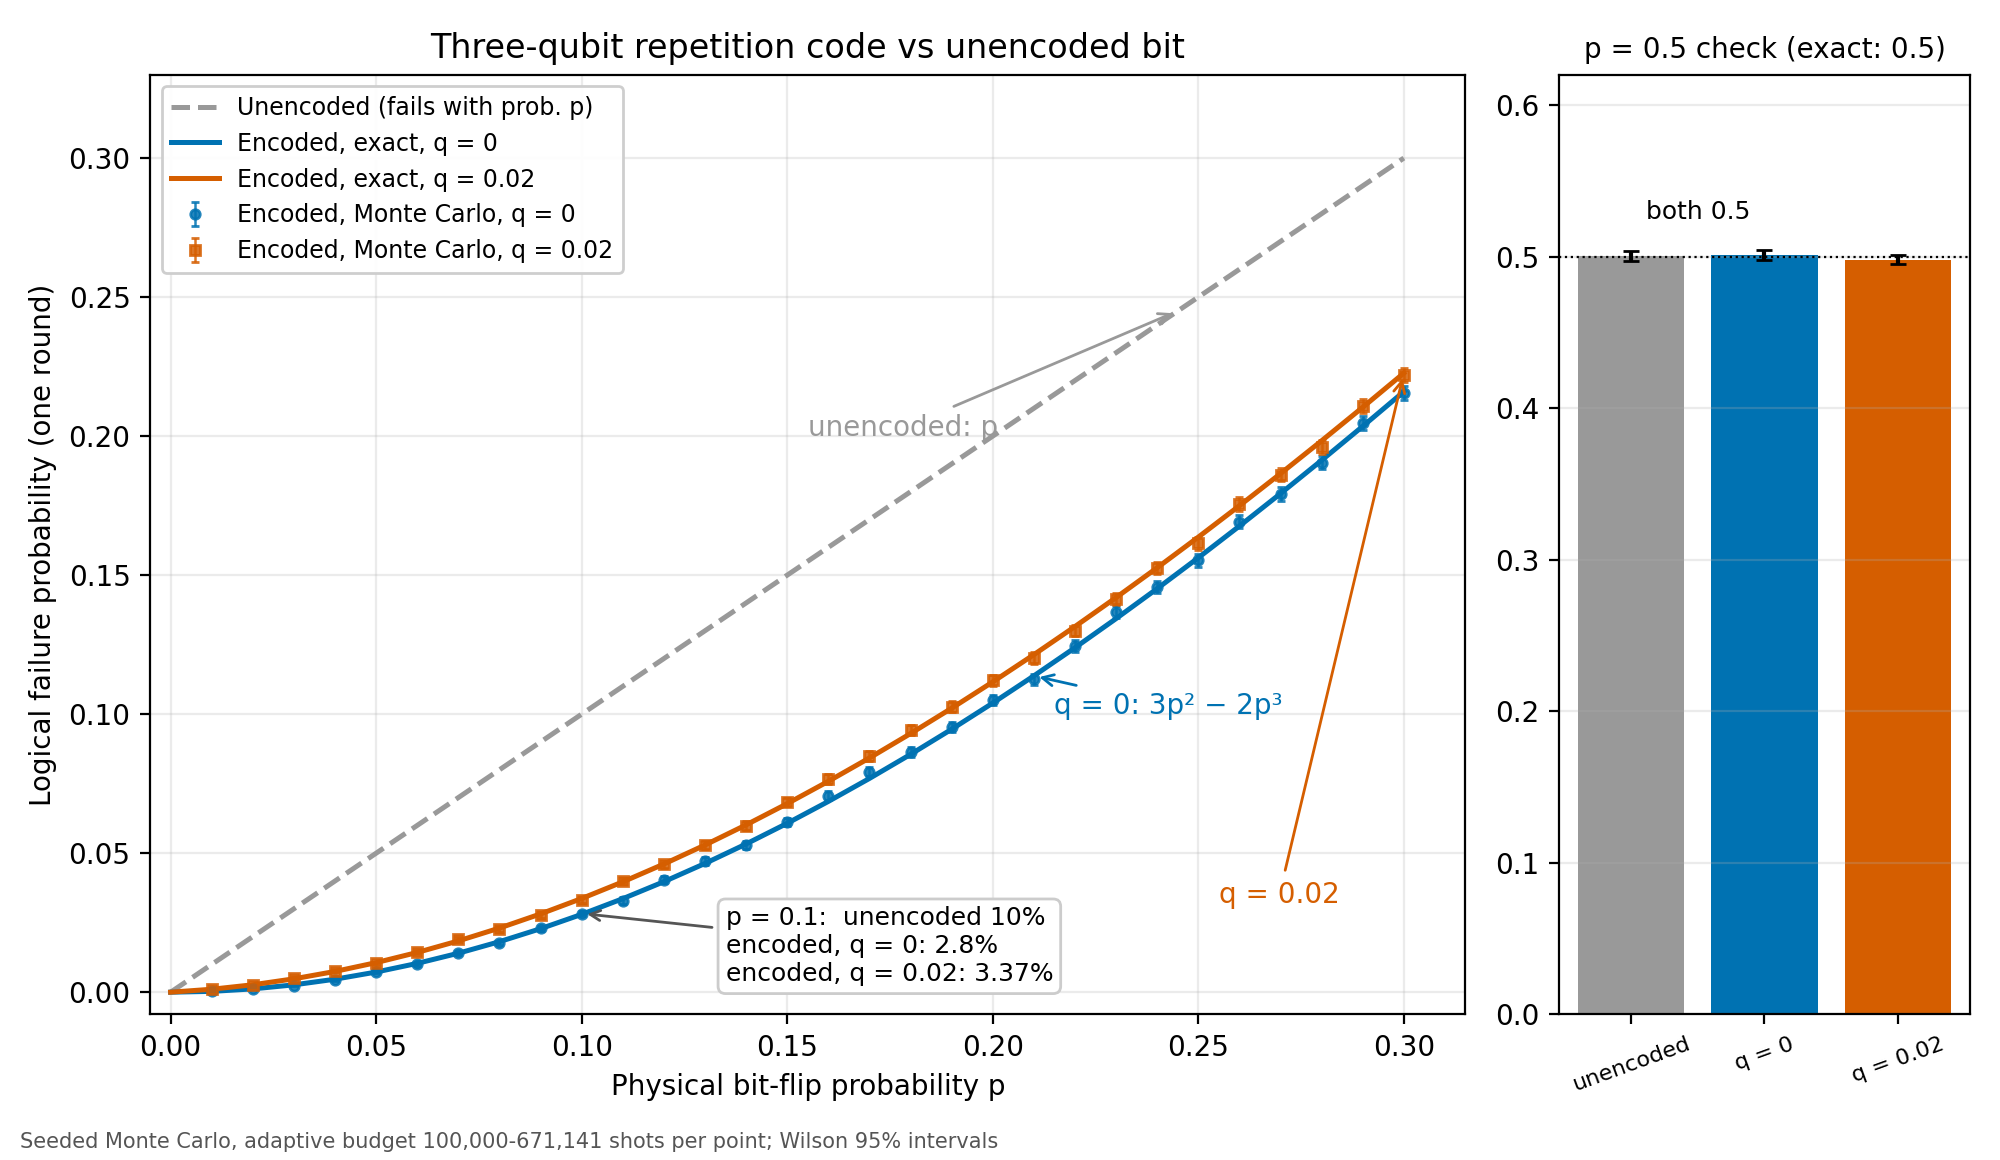

In [7]:
make_figure(RESULTS / "sweep.csv", RESULTS / "fig_sweep.png")
from IPython.display import Image, display
print("Figure written to results/fig_sweep.png")
display(Image(filename=str(RESULTS / "fig_sweep.png")))

The two short movies live in `results/`:
[anim_round.mp4](../results/anim_round.mp4) (26 s walkthrough of one
correction round in three verified scenarios) and
[anim_sweep.mp4](../results/anim_sweep.mp4) (28 s sweep with the same
records as the figure above). Both loop as GIFs in the same folder.

### Correction vs no feedback at p = 0.1

If the decoder **ignores the reports** and goes straight to the ideal final
majority, the logical failure rate is the clean law $L_0 = 2.8\%$ for either
$q$, because the reports are never used. With **perfect** parity reports,
correction returns every block to the code space. It corrects a single data
flip. Two or three flips can leave an **undetected logical X** - a weight-2
mask such as 110 produces the same reports as a single error on qubit 3, the
decoder flips that qubit, and the block ends as 111 with zero syndrome but
the wrong logical bit. At a 10% data-flip rate and a 2% error probability
per parity report, **6.64912%** of corrected blocks contain at least one
residual X, and **3.37024%** give the wrong final majority - a penalty of
**0.57024 percentage points** over taking the final majority without
feedback. Per qubit, the residual-X marginals are **4.656% / 3.39648% /
4.656%** (the decoder breaks the symmetry), and in **3.27888%** of blocks a
residual X remains while the ideal majority still gives the correct bit.
These are different physical questions from the terminal logical rate, and
all of them are verified against the oracle in the test suite. The $q = 0$
curve in the figure above is simultaneously the no-feedback rate.

## 3. Zero-failure handling

At $p = 0$ (and small $p$ with unlucky draws) zero failures may be observed.
The point estimate is 0 but the Wilson interval keeps a finite upper bound,
so the CSV never reads "0 ± 0" - the interval is the honest statement.

In [8]:
zero = frame[frame.p == 0.0]
zero[["p", "q", "logical_failure", "logical_failure_count",
      "logical_failure_ci_low", "logical_failure_ci_high"]]

,p,q,logical_failure,logical_failure_count,logical_failure_ci_low,logical_failure_ci_high
0,0.0,0.00,0.0,0,0.0,0.00004
1,0.0,0.02,0.0,0,0.0,0.00004


## 4. What one round of this model establishes - and what it leaves out

**Established.** For independent X errors with independent parity-report
flips, majority decoding with truthful reports reduces failure from
$\sim p$ to $\sim 3p^2$; readout noise $q$ adds the term
$(4q-2q^2)p(1-p)(1-2p)$, which vanishes at $p=0$, $p=1$ and $p=0.5$, and a
wrong report can leave a residual physical error *while* the logical bit
still reads correctly - the two observables are genuinely different.

**Left out.** Phase (Z) errors, gate and state-preparation noise (the model
is phenomenological, not circuit-level), repeated syndrome extraction across
rounds, and decoder statefulness. An arbitrary-state fidelity or a
fault-tolerance threshold claim would need its own definition and
experiment; the measured observable here is the failure probability of an
encoded **computational-basis bit** under ideal final majority readout.